# **AI 500 – Assignment 2**

**Part A:** Theory (50 marks) · **Part B:** End-to-End EDA and Data Preparation (50 marks)



---



# **Name: Muhammad Abdullah Naeem <br> Roll Number: 26280047**


---



### **How to use this template**
1. Write your answers in the cells marked. You must keep to the requested format. If a cell says maximum two sentences, don't go above two sentences.

3. For Part B, you must write the code, show the output and answer the questions breifly in the markdown cell.
4. Show your working in every calculation (A3(c) and A6), then fill in the result table.
5. Answer every part. Blank cells receive no marks.
8. **Need help with a topic?** Each question has a **📖 Read** line. It gives the section of the notes to read and the page numbers printed at the bottom of each page.



---



## **A1. Build the dataset in your head (8 marks)**

> **📖 Read:** 2.1 Data as a Constructed Record of Reality, especially 2.1.1 Data are produced, not simply found, 2.1.2 Fitness for Purpose (Q(D,T,C)) and Example 38, Predicting student dropout risk **pp. 173–179.**
>



---



### **A1.1 Target definitions (2 marks)**

Write three different definitions of "no-show". For each one, give the label of a patient who arrives **40 minutes late** (1 = no show, 0 = showed up).

**Your answer:**

| # | Definition of "no-show" (one sentence) | Label for the 40-minutes-late patient (0 or 1) |
|---|---|---|
| 1 | Strict/administrative, which is that the patient did not arrive for check-in by the scheduled start time (no grace period). | 1 |
| 2 | Grace-period rule, that is the patient did not arive within 15 minutes of the scheduled time, so the slot was released to someone else. | 1 |
| 3 | Clinical-encounter rule, meaning the patient was never seen by a clinician that day, regardless of how late they arrived. | 0 (if the clinic still saw them) |

### **A1.2 Variables (2 marks)**

Choose 4 variables to include and 2 to exclude. For each one, write Relevance, Privacy or Reliability as the reason type, then give a one line reason.

**Your answer:**

| Decision | Variable | Reason type | Reason (one line) |
|---|---|---|---|
| Include | Lead time, which is days between booking and appointment | Relevance | Longer waits give more time for plans to change and are a known strong driver of missed appointmnets. |
| Include | Patient's own prior no-show history (computed only from *earlier* appointments) | Relevance | Past behaviour is one of the best predictors of future attendance and is known at prediction time. |
| Include | SMS reminder sent (0/1) | Relevance | an intervention that the clinic controls and can act on, and that may change attendance. |
| Include | Age | Reliability | recorded routinely at registration, has few missing values and relates to attendance patterns. |
| Exclude | Full name, phone number or exact home address | Privacy | Directly identifying and adds no predictive value beyond coarser features such as neighbourhood. |
| Exclude | Self-reported alcoholism flag | Reliability | Heavily under-reported and recorded inconsistantly, so the flag reflects disclosure habits more than the condition. |

### **A1.3 Sampling (1 mark)**

The data come only from public clinics in one city

**Your answer:**

| | |
|---|---|
| Who is missing from the data? | patients of private clinics and insurance-based care. people in other cities and rural areas of Brazil, and people who never book an appointment at all (e.g. those who face access barriers). |
| one deployment where this would matter | deploying the call-list model in a rural municipality or a private hospital network. travel distances, income and booking habits differ there, so the learned patterns may not transfer and risk scores would be miscalibrated. |

### **A1.4 What could "NA" mean? (1 mark).**

Suppose `SMS_received` is blank for some rows. Give three different realities that the blank could stand for.

**Your answer:**

| # | What the blank could mean |
|---|---|
| 1 | No SMS was sent (it could be that the field was simply left empty instead of being recorded as 0). |
| 2 | An SMS was sent, but the delivery log was lost or never writen (such as a system outage or failed export). |
| 3 | SMS was not applicable: the patient has no mobile number on file or opted out of reminders. |

### **A1.5 Same name, different meaning (1 mark)**

Clinic A marks a no-show after 15 minutes. Clinic B marks it only if the patient never arrives. What goes wrong if their data are merged? Answer in 2–3 lines.

**Your answer**

The label `No-show = Yes` would mean two different things in the same column. a Clinic A patient who came 20 minutes late counts as a no-show, but the same patient at Clinic B counts as attended. the merged target is therefore inconsistent, so the model learns clinic-specific recording rules (and clinic can act as a proxy for the label) instead of real patient behaviour, and Clinic A will look artificially worse. the definitions must be harmonised to one rule, using arrival times if availble, before the data are combined.

### **A1.6 Fit for purpose? (1 mark)**

Is this dataset fit for each use?

**Your answer**

| Use | Fit? (Yes / No) | Reason (one line) |
|---|---|---|
| (i) Monthly attendance report | Yes | It is descriptive counting of recorded appointments over April–June, which the data cover well (with the caveat of only three months). |
| (ii) Tomorrow's call list | Partly / with conditions | It can work only if features are restricted to information available the evening before (no post-appointment fields) and the model is validated on later dates. |
| (iii) One national model for all of Brazil | No | the data come from public clinics in a single city, so they do not represent other regions, rural areas or private care. |
| (iv) Proving that SMS reminders *cause* attendance | No | This is observational data. SMS was not randomly assigned (e.g. it is sent mainly for appointments booked well in advance), so confounding prevents causal claims. |

## **A2. Synthetic data (3 marks)**

> **📖 Read:** 2.2.8 Synthetic Data (its uses, risks and validation dimensions), Example 43 and Table 6. **pp. 195–199.**
>


---

### **A2(a) (2 marks)**

Name two risks of sharing the synthetic copy. For each risk, name the validation dimension that would catch it. Choose one of: Fidelity, Utility, Privacy, Fairness, Coverage, Realism.

**Your answer:**

| # | Risk (one line) | Validation dimension |
|---|---|---|
| 1 | Re-identification, which is that the generator may memorise and also reproduce near-copies of real patients (especially rare combinations such as a 102-year-old in a small neighbourhood). | Privacy |
| 2 | The synthetic data may not preserve the real relationships (e.g. lead time vs no-show, age vs no-show), so the vendor's scheduling product is tuned on false patterns. | Fidelity (checked in practice by Utility, such as train on synthetic, test on real) |

### **A2(b) (1 mark)**

Statement: *"It's synthetic, so it's anonymous."*

**Your answer**

| True / False | Justification (one line) |
|---|---|
| False | Synthetic records can still leak information about real patients through memorised near-duplicates, or it could be rare outliers or membership inference, so privacy must be tested, not assumed. |

## **A3. Spot the flaw (10 Marks)**

> **📖 Read:**
> - 2.3 Data Quality, the six dimensions, **pp. 200–213** (Example 44 is a close model for this question)
> - 2.5.2 Outliers, **pp. 222–226**
> - 2.5.3 Duplicate records, Inconsistent labels, Inter-annotator agreement, Unit-aware schemas, **pp. 226–231**
> - 2.5.4 Class imbalance, **pp. 232–234**
>



---



<br>

| # | AppointmentID | PatientId | Gender | Age | Weight_kg | Neighbourhood | ScheduledDay | AppointmentDay | SMS | No-show |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 5642903 | 2.98725e+13 | F | 62 | 71 | JARDIM DA PENHA | 2016-04-29 | 2016-04-29 | 0 | No |
| 2 | 5642503 | 558997776694438 | M | 56 | 80 | JARDIM DA PENHA | 2016-04-29 | 2016-04-29 | 0 | No |
| 3 | 5642549 | 4262962299951 | Female | 8 | 27 | MATA DA PRAIA | 2016-04-29 | 2016-04-29 | 0 | No |
| 4 | 5642828 | 867951213174 | f | N/A | 64 | PONTAL DE CAMBURI | 2016-04-27 | 2016-04-29 | 0 | No |
| 5 | 5642494 | 8841186448183 | F | 34 | 154 | JARDIM DA PENHA | 2016-04-29 | 2016-04-29 | 0 | No |
| 6 | 5626772 | 95985133231274 | F | 76 |  | REPÚBLICA | 2016-04-27 | 2016-04-29 | 0 | Yes |
| 7 | 5630279 | 733688164476661 | M | 23 | 78 | GOIABEIRAS | 2016-04-27 | 2016-04-29 | 0 | Yes |
| 8 | 5630279 | 733688164476661 | M | 23 | 78 | GOIABERAS | 2016-04-27 | 2016-04-29 | 0 | Yes |
| 9 | 5633460 | 12154843752835 | M | -1 | 3.2 | CONQUISTA | 2016-04-28 | 2016-04-29 | 0 | No |
| 10 | 5650093 | 78124564369297 | F | 115 | 58 | ANDORINHAS | 2016-05-03 | 2016-04-29 | 1 | No |
| 11 | 5634718 | 3449833394123 | F | 38 | 65 | NOVA PALESTINA | 2016-04-26 | 2016-04-29 | 1 | 1 |
| 12 | 5639264 | 2263865652 | male | 19 | 70 | SANTO ANDRÉ | 2016-04-26 | 2016-04-29 | 1 | No |



### **A3(a) (7 Marks).**

List every issue you can find. There are at least 12. Give each issue its own row, and add rows if you need them.
- **Quality dimension:** choose one of Completeness, Accuracy, Consistency, Timeliness, Representativeness, Measurement error.
- **Row(s):** write "All" if the issue affects the whole table.

**Your answer:**

| # | Row(s) | Issue (what is wrong) | Quality dimension | Fix (what you would do) |
|---|---|---|---|---|
| 1 | 1 | `PatientId` is stored in scientific notation like (2.98725e+13), so digits are lost and the ID cannot be matched to other rows. | Accuracy | Store IDs as strings/int64 and re-export from the source system. |
| 2 | All | `PatientId` has inconsistent lengths/formats (10 to 15 digits, some floats), which suggests IDs were truncated or cast differently. | Consistency | define an ID schema (fixed type and length) and validate every row against it. |
| 3 | 3, 4, 12 | Gender is coded inconsistently: `Female`, `f`, `male` alongside `F`/`M`. | Consistency | Map all variants to a controlled vocabulary {F, M}. |
| 4 | 4 | Age is `N/A` (a missing value hidden as a text string). | Completeness | Convert to a true NaN, recover it from the patient's other records if possible, or flag it and impute. |
| 5 | 5 | Weight 154 kg for a 34-year-old stands out and could be a unit error (lb vs kg) or a typing error. | Measurement error | Check the source/unit. flag it as a suspect outlier instead of silently deleting it. |
| 6 | 6 | `Weight_kg` is blank. | Completeness | Treat as NaN, add a missing-indicator and use a suitable imputation (or leave missing if weight is not needed). |
| 7 | 7, 8 | Same `AppointmentID` and patient appear twice, so it is a duplicate record (one copy has a spelling variant). | Accuracy (duplicate) | De-duplicate on `AppointmentID`, keeping the version with the valid neighbourhood name. |
| 8 | 8 | Neighbourhood mispelt `GOIABERAS` instead of `GOIABEIRAS`. | Consistency | Validate against the official neighbourhood list and correct misspellings with fuzzy matching. |
| 9 | 9 | Age = −1 is an impossible value (and weight 3.2 kg only fits a newborn). | Accuracy | Treat −1 as a code (e.g. an infant under 1 year / unknown), decode it to age 0, and document the rule. |
| 10 | 10 | `ScheduledDay` (2016-05-03) is *after* `AppointmentDay` (2016-04-29), so the booking happens after the appointment. | Consistency | Flag rows with negative lead time. verify the timestamps or exclude them from the analysis. |
| 11 | 10 | Age 115 is implausible (and a weight of 58 kg is not decisive either way). | Accuracy | Check against date of birth. set to NaN if it cannot be verified. |
| 12 | 11 | Target `No-show` = `1` while all other rows use `Yes`/`No`. | Consistency | Map the target to one encoding (Yes/No, then 1/0) and confirm what `1` meant in the source. |
| 13 | All (esp. 9) | `Weight_kg` is recorded at different precisions (whole kg in most rows, 3.2 in row 9), which suggests different scales or protocols at the triage desk. | Measurement error | Record the instrument and protocol, standardise the precision, and store units in the schema. |
| 14 | All | Date columns are dates only. the booking *time* and the appointment time are lost, so the same-day lead time (e.g. rows 1–3, 5) cannot be measured precisly. | Timeliness | Keep the full timestamps from the source system. |
| 15 | All | Every appointment is on 2016-04-29 (one day) and from a few neighbourhoods. the sample does not represent the whole period or city. | Representativeness | Sample across dates and neighbourhoods. do not draw conclusions from this extract alone. |

### **A3(b) (1 mark).**

Row 9 has an age of −1 and a weight of 3.2 kg.

**Your answer:**

| Decision (*Delete as error* / *Decode as a code*) | Reasoning (one line) |
|---|---|
| Decode as a code | A weight of 3.2 kg is exactly what a newborn weighs, so −1 is most likely a system code for "under 1 year old" (an infant), and deleting it would systematically remove babies from teh data. |

### **A3(c) (2 marks).**

Two receptionists independently coded the reason for 50 missed appointments as "patient-side" or "clinic-side". They agreed on 40. Receptionist 1 chose "patient-side" 30 times. Receptionist 2 chose it 28 times.

Working (show p_o, p_e and κ; see footnote 221 on p. 229 for Cohen's κ):

**Your answer**

**Working:**

- Observed agreement: $p_o = 40/50 = 0.80$
- Receptionist 1: patient-side $= 30/50 = 0.60$, clinic-side $= 20/50 = 0.40$
- Receptionist 2: patient-side $= 28/50 = 0.56$, clinic-side $= 22/50 = 0.44$
- Chance agreement: $p_e = (0.60)(0.56) + (0.40)(0.44) = 0.336 + 0.176 = 0.512$
- $\kappa = \dfrac{p_o - p_e}{1 - p_e} = \dfrac{0.80 - 0.512}{1 - 0.512} = \dfrac{0.288}{0.488} = 0.59$

| Quantity | Value |
|---|---|
| Observed agreement p_o | 0.80 |
| Chance agreement p_e | 0.51 |
| Cohen's κ | 0.59 |
| Interpretation (one line) | Moderate agreement: much of the raw 80% agreement is what chance alone would produce, so the labels are only moderately reliable. |
| Why a majority vote would not guarantee the true reason (one line) | Receptionists share the same information and biases (they never talk to the patient about why they missed), so a majority can agree on the same wrong reason. agreement measures consistency, not truth. |

## **A4. Why is it missing? (9 marks)**

> **📖 Read:** 2.5.1 Missing values, pp. 218–222. Focus on:
> - the three mechanisms MCAR, MAR and MNAR, with Examples 45–47 (pp. 219–220)
> - Approaches to handling missing values and Model-based imputation, especially the Caution about lactate and footnote 212 (pp. 221–222)
>



---

<br>

**The cases: (3 marks each)**
1. A server outage wiped the SMS logs for three randomly timed afternoons.
2. `HbA1c` is recorded only when a doctor suspects poorly controlled diabetes. A teammate wants to fill the blanks with a KNN imputer.
3. `Neighbourhood` is blank for patients who have no fixed address.

**Your answer:**

| Case | Mechanism | Handling strategy | Justification (one line) |
|---|---|---|---|
| 1 | MCAR | Complete-case analysis (drop the affected rows) or simple imputation, and record the outage. | The outage timing is random and unrelated to patients or attendance, so the remaining rows are an unbiased sample and only statistical power is lost. |
| 2 | MNAR | Do not impute the value. add a binary indicator `HbA1c_measured`, keep the value where present, and use domain knowledge or a sensitivity analysis. | Whether HbA1c is missing depends on the (unobserved) level of diabetes control itself, so the fact that it was *measured* is informative in its own right. |
| 3 | MNAR | Keep the rows and code the blank as its own category, e.g. `No fixed address`, plus a missing-indicator. | The missingness is caused by the patient's housing situation, which is itself linked to attendance, so dropping or imputing would erase a vulnerable group. |

**Case 2, extra line (counts toward case 2's 3 marks):** Why would the KNN imputer be a mistake here?

**Your answer**

**Answer:**

KNN imputation assumes the missing values resemble those of similar patients who *were* tested (i.e. MAR), but here the patients with a recorded HbA1c are exactly the ones suspected of poor control. the imputer would therefore fill untested, probably well-controlled patients with high, "poorly controlled" values borrowed from tested patients. this creates fake clinical information and distorts the distribution. it also throws away the informative signal that *no test was ordered*.

## **A5. Find every leak (8 marks)**

> **📖 Read:** 2.6 *Data Leakage*, pp. 239–248. Focus on:
> - 2.6.2 Target leakage, and Example 54 on sepsis (p. 240)
> - 2.6.3 Train–test contamination (pp. 241–242)
> - 2.6.4 Cross-validation variants (pp. 242–244)
> - 2.6.5 Temporal leakage (pp. 244–245)
> - 2.6.6 Group leakage, and Example 55 on churn (pp. 245–247)
> - 2.6.7 Site leakage (p. 247)
> - 2.6.8 the prevention checklist (pp. 247–248)
>
> **What to do:** A teammate reports **AUC = 0.97** from the pipeline below. Find the leak in each step.



---


 <br>

**The pipeline:**
1. For each patient, `past_noshow_rate` is the share of **all** of that patient's appointments in the file that were missed.
2. `reminder_call_outcome` is added. Staff log this the day *after* the appointment.
3. StandardScaler and SMOTE are run on the full dataset, and then 5-fold `KFold` is used.
4. Many patients have 10 or more appointments, and they appear in both training and validation folds.
5. The model will be deployed next in a different city, but it was tested only on Vitória's neighbourhoods.
<br>

### **A5(a) (5 marks).**

For each step, name the leakage type (Target, Train-test contamination, Temporal, Group or Site) and give the fix. A step can have more than one type.

**Your answer**

| Step | Leakage type | Fix (one line) |
|---|---|---|
| 1 | Target leakage + Temporal leakage | Compute `past_noshow_rate` only from the patient's appointments *before* the current appointment date (an expanding window that excludes the current row). |
| 2 | Target leakage (Temporal) | Drop `reminder_call_outcome`. it is recorded the day after the appointment, so it is not available when the call list is produced the evening before. |
| 3 | Train–test contamination | Put StandardScaler and SMOTE inside an (imblearn) pipeline that is fitted only on each training fold. never oversample the validation/test data. |
| 4 | Group leakage | Split by patient (`GroupKFold` / `StratifiedGroupKFold` on `PatientId`) so all of a patient's appointments are in the same fold. |
| 5 | Site leakage | Evaluate on held-out sites (leave-neighbourhood-out), and validate on data from the new city before deployment, recalibrating if neccessary. |

### **A5(b) (3 marks)**

Which pipeline step does each evaluation setup fix?

**Your answer**

| Evaluation setup | Step(s) it fixes | Why (one line) |
|---|---|---|
| `StratifiedGroupKFold` | Step 4 (and it helps step 1) | Groups by `PatientId` so the same patient never appears in both training and validation, while keeping the no-show ratio similar in every fold. |
| `TimeSeriesSplit` | Steps 1 and 2 (temporal) | Always trains on earlier appointments and validates on later ones, which mirrors deployment and exposes features that use future information. |
| Neighbourhood hold-out | Step 5 | Tests the model on neighbourhoods it never saw during training, which estimates how it will perform at a new site such as a different city. |

## **A6. Crunch the numbers (12 marks)**

> **What to do:** Show your working in each **Working** box, then fill in the result table. Round to 2 decimal places.



---



### **6.1 Outliers in waiting time (3 marks)**

> **📖 Read:** 2.5.2 Outliers: z-score and IQR on p. 223 (with footnote 213), and the Box-Cox and shifted Box-Cox transforms on pp. 224–225 (Table 18).

Data (`wait_days` for 11 appointments): **0, 0, 1, 2, 3, 4, 6, 7, 10, 14, 60**

<br>

**(a) IQR rule (1.5 marks).**

Use linear interpolation, as `np.percentile` does.

**Your answer**

**Working:**

Sorted data ($n = 11$): 0, 0, 1, 2, 3, 4, 6, 7, 10, 14, 60. with linear interpolation the position of the $p$-th percentile (0-indexed) is $(n-1)p$.

- Q1: position $10 \times 0.25 = 2.5$ → between $x_{(2)} = 1$ and $x_{(3)} = 2$ → $1 + 0.5(2-1) = 1.5$
- Q3: position $10 \times 0.75 = 7.5$ → between $x_{(7)} = 7$ and $x_{(8)} = 10$ → $7 + 0.5(10-7) = 8.5$
- IQR $= 8.5 - 1.5 = 7$
- Lower fence $= 1.5 - 1.5(7) = 1.5 - 10.5 = -9$
- Upper fence $= 8.5 + 1.5(7) = 8.5 + 10.5 = 19$
- Only 60 lies outside [−9, 19].

| Q1 | Q3 | IQR | Lower fence | Upper fence | Points flagged |
|---|---|---|---|---|---|
| 1.50 | 8.50 | 7.00 | −9.00 | 19.00 | 60 |

**(b) z-score rule (1.5 marks)**

Using the sample standard deviation (divisor n − 1), compute the z-scores of 14 and 60. Which values does the rule |z| > 3 flag?

**Your answer**

**Working:**

- Mean: $\bar x = 107 / 11 = 9.73$
- $\sum x^2 = 4011$, so $\sum (x-\bar x)^2 = 4011 - 107^2/11 = 4011 - 1040.82 = 2970.18$
- Sample variance $s^2 = 2970.18 / 10 = 297.02$ → $s = 17.23$
- $z(14) = (14 - 9.73)/17.23 = 0.25$
- $z(60) = (60 - 9.73)/17.23 = 2.92$
- No value has $|z| > 3$: the outlier 60 inflates both the mean and the SD, so it hides itself (the masking effect).

| Mean | Sample SD | z(14) | z(60) | Values flagged |
|---|---|---|---|---|
| 9.73 | 17.23 | 0.25 | 2.92 | None |

### **6.2 A leak you can calculate (3 marks)**

> **📖 Read:** 2.6.3, Preprocessing contamination: μ_train vs μ_all, pp. 241–242.

**(a) (1.5 marks).** The training-set ages are **20, 30, 40, 50** and the test-set ages are **80, 90**. Use the population SD (divide by n), as `StandardScaler` does.

**Your answer**

**Working:**

(a) Training data only (20, 30, 40, 50):
- $\mu = 140/4 = 35$
- $\sigma^2 = [(-15)^2 + (-5)^2 + 5^2 + 15^2]/4 = 500/4 = 125$ → $\sigma = 11.18$
- $z(90) = (90 - 35)/11.18 = 4.92$

(b) All six patients (20, 30, 40, 50, 80, 90):
- $\mu = 310/6 = 51.67$
- $\sigma^2 = [31.67^2 + 21.67^2 + 11.67^2 + 1.67^2 + 28.33^2 + 38.33^2]/6 = 3883.33/6 = 647.22$ → $\sigma = 25.44$
- $z(90) = (90 - 51.67)/25.44 = 1.51$

| Method | Mean | SD | Standardized value for age 90 |
|---|---|---|---|
| (a) Training data only | 35.00 | 11.18 | 4.92 |
| (b) All six patients (leaky) | 51.67 | 25.44 | 1.51 |

**(b) (1.5 marks).** Why does the leaky value look "tamer"? Answer in one line.

**Your answer**

**Answer:**

The test patients' own ages pull the mean up and widen the SD, so the scaler has already "seen" the test data. age 90 then looks ordinary (1.51) instead of far outside the training range (4.92), which hides the distribution shift the model will face.

### **6.3 Why accuracy lies (3 marks)**

> **📖 Read:** §2.5.4, Why accuracy can be misleading (p. 232) and Platt scaling, with Examples 53–54 (pp. 235–237).

The test set has 1,000 appointments, of which 200 were missed. The model flags 210 patients, and 120 of them really do miss.

**(a) (2 marks).** Fill in the model's confusion counts, then the metrics.

**Your answer**

Working: TP = 120 (flagged and missed), FP = 210 − 120 = 90, FN = 200 − 120 = 80, TN = 1000 − 120 − 90 − 80 = 710.
Baseline: predicts no one misses → accuracy = 800/1000 = 0.80, recall = 0/200 = 0.
Model: accuracy = (120 + 710)/1000 = 0.83; precision = 120/210 = 0.57; recall = 120/200 = 0.60.

| TP | FP | FN | TN |
|---|---|---|---|
| 120 | 90 | 80 | 710 |

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| Baseline ("always shows up") | 0.80 | n/a | 0.00 |
| Your model | 0.83 | 0.57 | 0.60 |

**(b) (1 mark).** Using P(miss) = 1 / (1 + exp(A·s + B)) with A = −2, B = 1.5 and s = 1:

**Your answer**

**Working:**

- $A s + B = (-2)(1) + 1.5 = -0.5$
- $\exp(-0.5) = 0.6065$
- $P(\text{miss}) = 1/(1 + 0.6065) = 1/1.6065 = 0.62$

| P(miss) |
|---|
| 0.62 |

### **6.4 Fairness from counts (3 marks)**

> **📖 Read:** 2.8.8 Fairness, with the metric definitions and Example 62 (pp. 266–267).

| | Appointments | Missed | Flagged | Flagged *and* missed |
|---|---|---|---|---|
| Women | 600 | 150 | 150 | 90 |
| Men | 400 | 50 | 60 | 30 |

**(a) (1.5 marks).** Compute each metric for each group.

**Your answer**

**Working:**

- Women: TP = 90, FP = 150 − 90 = 60, positives = 150, negatives = 600 − 150 = 450.
  PPR = 150/600 = 0.25; TPR = 90/150 = 0.60; FPR = 60/450 = 0.13; PPV = 90/150 = 0.60.
- Men: TP = 30, FP = 60 − 30 = 30, positives = 50, negatives = 400 − 50 = 350.
  PPR = 60/400 = 0.15; TPR = 30/50 = 0.60; FPR = 30/350 = 0.09; PPV = 30/60 = 0.50.

| Group | Positive prediction rate | TPR | FPR | PPV |
|---|---|---|---|---|
| Women | 0.25 | 0.60 | 0.13 | 0.60 |
| Men | 0.15 | 0.60 | 0.09 | 0.50 |

**(b) (1.5 marks).** Which criteria hold?
Give a one-line justification for each.

**Your answer**

| Criterion | Holds? (Yes / No) | Evidence (which numbers) |
|---|---|---|
| Demographic parity | No | Positive prediction rates differ: 0.25 for women vs 0.15 for men. |
| Equal opportunity | Yes | TPRs are equal: 0.60 for both groups. |
| Equalized odds | No | TPRs match, but FPRs differ (0.13 vs 0.09), and equalized odds needs both to match. |
| Predictive parity | No | PPVs differ: 0.60 for women vs 0.50 for men. |

---


# **Part B: Practical EDA & Data Preparation**



---



**Dataset:** https://www.kaggle.com/datasets/joniarroba/noshowappointments

Medical Appointment No Shows, MissedCare

We will use the same dataset and scenario introduced in Part A. The practical section should continue the MissedCare problem rather than introducing a new dataset.

### **Instructions:**


1.   Complete all questions in a Jupyter Notebook.
2.   For each question, provide the required code, output/visualization, and brief interpretation.
3. Your interpretations should be based on the results you obtain rather than generic statements.
4. Use appropriate visualizations and justify your choices where requested.
Do not create a separate written report.

## **B1. Understanding and Assessing the Dataset (10 Marks)**

Load the MissedCare dataset and perform an initial assessment of its structure and quality.

**(a) Dataset structure and quality: (4 Marks)**

Report the number of observations and variables, identify the numerical, categorical, binary and temporal variables and investigate missing values and duplicate records.

In [4]:
## your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Looooad the raw file once and work on a copy
raw = pd.read_csv("KaggleV2-May-2016.csv")
df = raw.copy()

print("Shape:", df.shape)
print(f"Observations: {df.shape[0]:,} | Variables: {df.shape[1]}")
print()
df.info()
display(df.head())

# Variable types (by meaning, not only by dtypeeee)
id_vars          = ["PatientId", "AppointmentID"]
numerical_vars   = ["Age", "Handcap"]              # Handcap is an integer count 0-4
categorical_vars = ["Gender", "Neighbourhood", "No-show"]
binary_vars      = ["Scholarship", "Hipertension", "Diabetes", "Alcoholism", "SMS_received"]
temporal_vars    = ["ScheduledDay", "AppointmentDay"]
print("Identifiers :", id_vars)
print("Numerical   :", numerical_vars)
print("Categorical :", categorical_vars)
print("Binary (0/1):", binary_vars)
print("Temporal    :", temporal_vars, "(stored as text/object, need conversion)")

# Missingggg values
print("\nMissing valuesssssssss per column:")
print(df.isna().sum())

# Duplicates
print("\nFullyyy duplicatedddd rows:", df.duplicated().sum())
print("Duplicatedddd AppointmentID:", df["AppointmentID"].duplicated().sum())
print("Duplicates ignoring AppointmentID:",
      df.drop(columns="AppointmentID").duplicated().sum())
print("Unique patients:", df["PatientId"].dropna().nunique(),
      f"({df.shape[0] / df['PatientId'].dropna().nunique():.2f} appointments per patient on average)")

# Hidden quality problems not visible as NaN
print("\nUniquee values of categorical/binary columns:")
for c in ["Gender", "No-show", "Handcap"] + binary_vars:
    unique_vals = df[c].dropna().unique().tolist()
    print(f"  {c}: {sorted(unique_vals)}")
print("Neighbourhoods:", df["Neighbourhood"].dropna().nunique())
print("Rows with Age < 0:", (df["Age"] < 0).sum(), "| Age == 0:", (df["Age"] == 0).sum(),
      "| Age > 100:", (df["Age"] > 100).sum())

Shape: (110527, 14)
Observations: 110,527 | Variables: 14

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


Identifiers : ['PatientId', 'AppointmentID']
Numerical   : ['Age', 'Handcap']
Categorical : ['Gender', 'Neighbourhood', 'No-show']
Binary (0/1): ['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'SMS_received']
Temporal    : ['ScheduledDay', 'AppointmentDay'] (stored as text/object, need conversion)

Missing valuesssssssss per column:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Fullyyy duplicatedddd rows: 0
Duplicatedddd AppointmentID: 0
Duplicates ignoring AppointmentID: 618
Unique patients: 62299 (1.77 appointments per patient on average)

Uniquee values of categorical/binary columns:
  Gender: ['F', 'M']
  No-show: ['No', 'Yes']
  Handcap: [0, 1, 2, 3, 4]
  Scholarship: [0, 1]
  Hipertension: [0, 1]
  Diabetes: [0, 1]
  Alcoholis

**(b) Descriptive statistics (4 marks):**

Generate appropriate descriptive statistics for the numerical variables. For Age, additionally report the minimum, Q1, median, Q3, maximum and IQR.

In [5]:
## your code here
num_cols = ["Age", "Handcap", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "SMS_received"]
display(df[num_cols].describe().T.round(3))

# Binary vaaaariables: prevalence (the mean is the share of 1s)
prev = (df[["Scholarship", "Hipertension", "Diabetes", "Alcoholism", "SMS_received"]].mean() * 100).round(2)
print("Prevalence of binary variables (% of appointments = 1):")
print(prev.to_string())

print("\nHandcappppp value counts:")
print(df["Handcap"].value_counts().sort_index().to_string())

# Age: five-number summary and IQR
age = df["Age"]
q1, med, q3 = age.quantile([0.25, 0.5, 0.75])
age_summary = pd.Series({
    "Min": age.min(), "Q1": q1, "Median": med, "Q3": q3,
    "Max": age.max(), "IQR": q3 - q1,
    "Mean": round(age.mean(), 2), "Std": round(age.std(), 2),
    "Skewness": round(age.skew(), 3),
})
print("\nAgeee summaryyy:")
print(age_summary.to_string())
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"IQR fences: [{lo}, {hi}] -> {((age < lo) | (age > hi)).sum()} ages outside the fences")

,count,mean,std,min,25%,50%,75%,max
Age,110527.0,37.089,23.110,-1.0,18.0,37.0,55.0,115.0
Handcap,110527.0,0.022,0.162,0.0,0.0,0.0,0.0,4.0
Scholarship,110527.0,0.098,0.298,0.0,0.0,0.0,0.0,1.0
Hipertension,110527.0,0.197,0.398,0.0,0.0,0.0,0.0,1.0
Diabetes,110527.0,0.072,0.258,0.0,0.0,0.0,0.0,1.0
Alcoholism,110527.0,0.030,0.172,0.0,0.0,0.0,0.0,1.0
SMS_received,110527.0,0.321,0.467,0.0,0.0,0.0,1.0,1.0


Prevalence of binary variables (% of appointments = 1):
Scholarship      9.83
Hipertension    19.72
Diabetes         7.19
Alcoholism       3.04
SMS_received    32.10

Handcappppp value counts:
Handcap
0    108286
1      2042
2       183
3        13
4         3

Ageee summaryyy:
Min          -1.000
Q1           18.000
Median       37.000
Q3           55.000
Max         115.000
IQR          37.000
Mean         37.090
Std          23.110
Skewness      0.122
IQR fences: [-37.5, 110.5] -> 5 ages outside the fences


**(c) Initial observations (2 marks):**

Based on your analysis, identify at least two observations about the structure or quality of the dataset that should be considered before proceeding with further analysis.

**Answer:**

1. **"Zero missing values" hides several quality problems.** `isna()` reports no missing values, but the data contain one impossible age (−1), 3,539 appointments with age 0 (possibly infants or a default value), and 7 ages above 100 (maximum 115). there are also 5 appointments whose `ScheduledDay` is *after* the `AppointmentDay` (a negative waiting time), which only becomes visible after converting the dates. these rows need to be decoded, verified or removed. they cannot be taken at face value.
2. **Rows are appointments, not patients.** there are 110,527 appointments but only 62,299 unique patients (1.77 each on average), and 618 rows are identical on every column except `AppointmentID` (same patient, same booking time, same day). observations are therefore not independant, so a random row-level split would put the same patient in both training and test sets (group leakage). any split must be grouped by `PatientId`.
3. **Types and encodings need fixing before analysis.** `ScheduledDay`/`AppointmentDay` are stored as text, and `PatientId` is a float (in scientific notation, so it cannot safely be used as an ID). `Handcap` is a 0–4 count and not binary as its name suggests (only 199 rows > 1), and the target `No-show` is a Yes/No string with "Yes" = missed.
4. **The target is imbalanced and some flags are rare.** about 20% of appointments are no-shows (80/20), so accuracy alone would be misleading. Alcoholism (3.0%), Handcap (2.0%) and Diabetes (7.2%) are rare, so thier subgroup rates rest on relatively few cases.

## **B2. Exploring Distributions and Relationships (10 Marks)**

Use appropriate visualizations to investigate the distributions of important variables and their relationships with the target variable, No-show.

Your analysis must include:

*   the distribution of Age
*   the distribution of at least two relevant categorical/binary variables;
the relationship between Age and No-show
*   a correlation heatmap for appropriate numerical/binary variables.


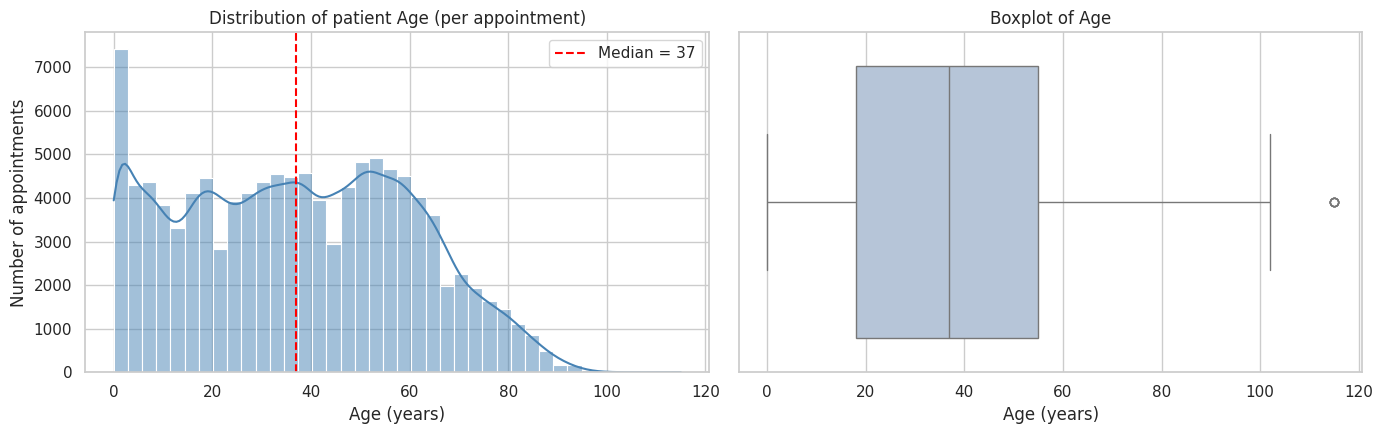

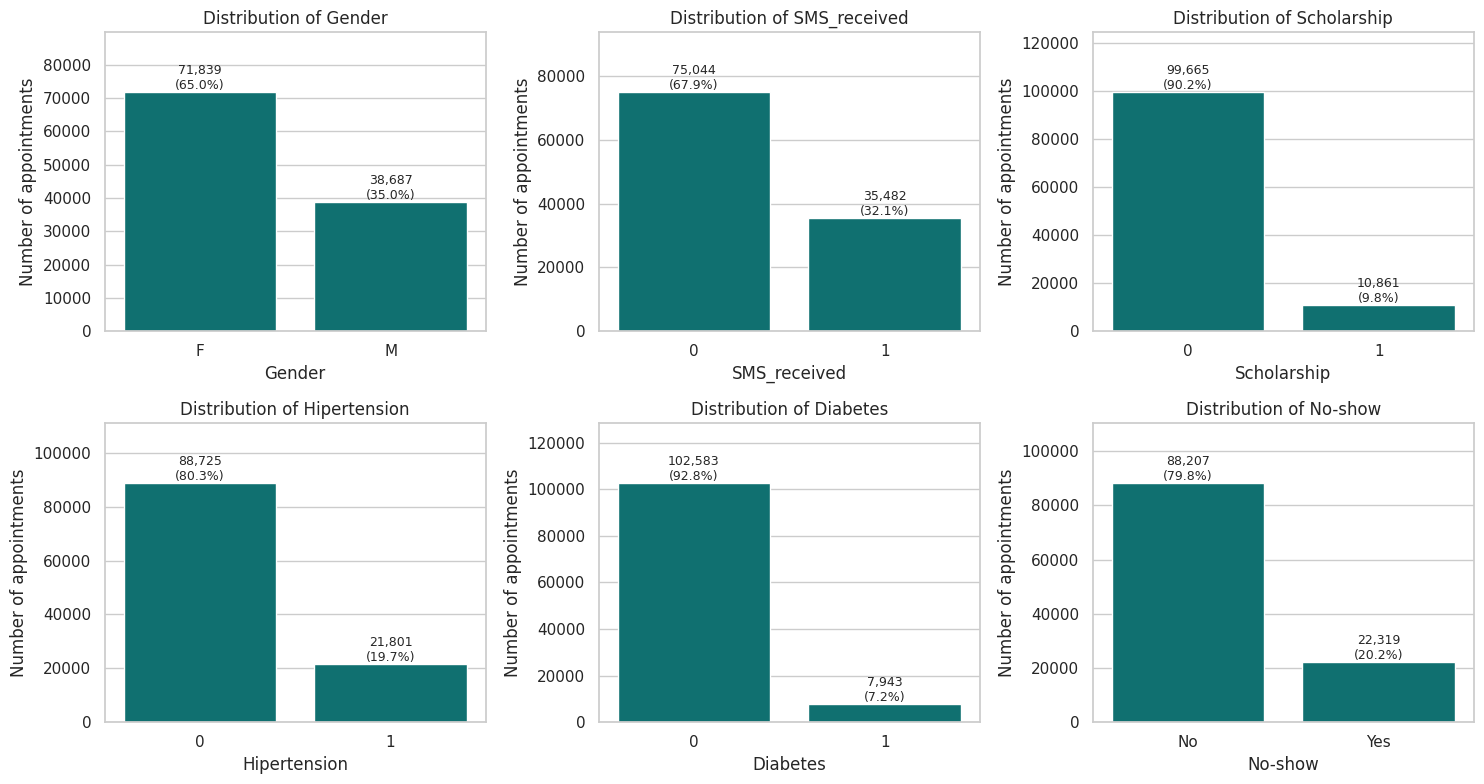

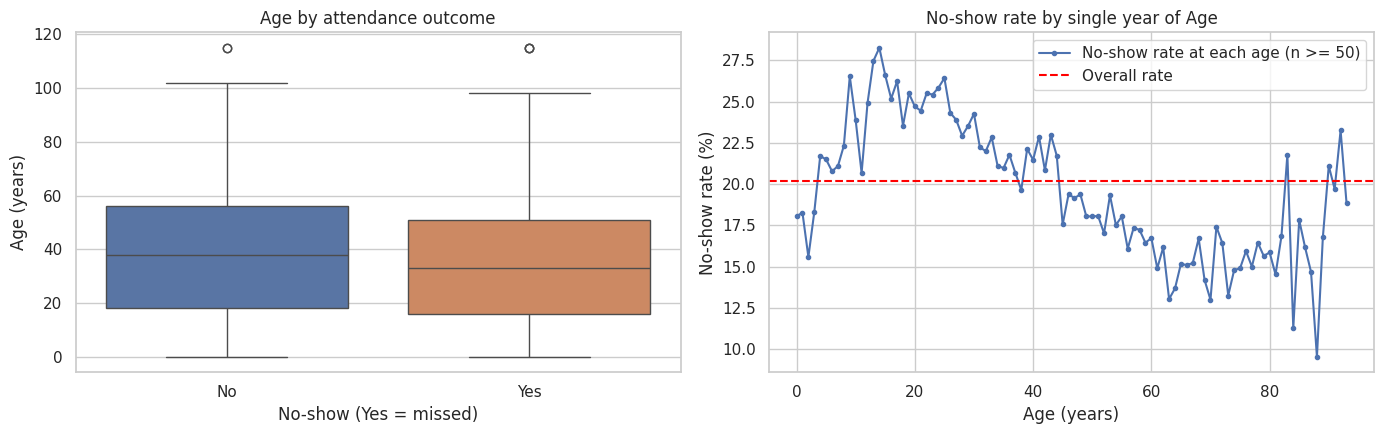

           count  mean   std  min   25%   50%   75%    max
No-show                                                   
No       88207.0  37.8  23.3  0.0  18.0  38.0  56.0  115.0
Yes      22319.0  34.3  22.0  0.0  16.0  33.0  51.0  115.0


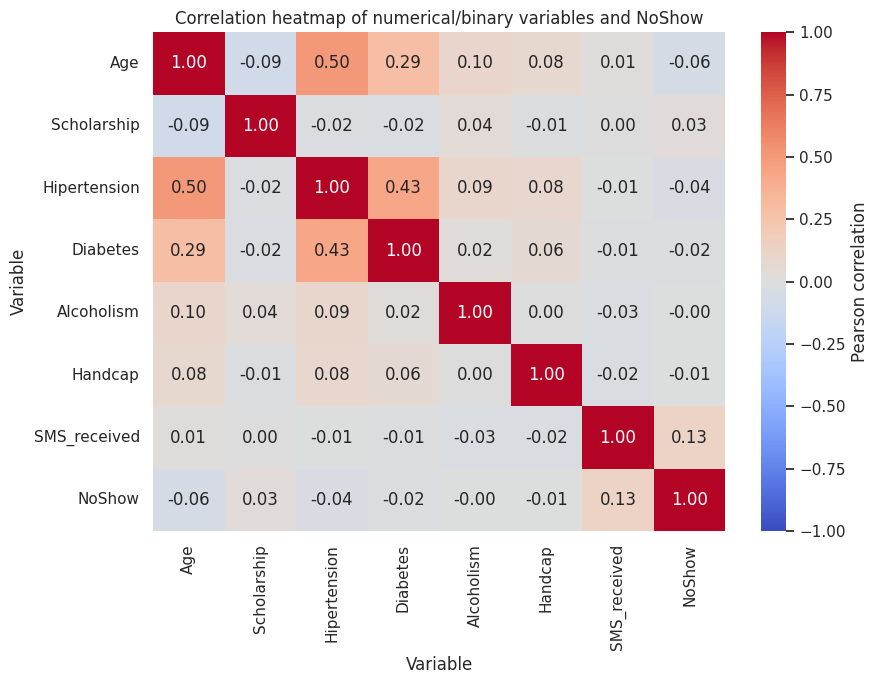

Correlation with NoShow:
Age            -0.060
Hipertension   -0.036
Diabetes       -0.015
Handcap        -0.006
Alcoholism     -0.000
Scholarship     0.029
SMS_received    0.126


In [6]:
## your code here
df["NoShow"] = (df["No-show"] == "Yes").astype(int)   # 1 = missed, 0 = attended
eda = df[df["Age"] >= 0].copy()                      # drop the single impossible age (-1) for plotting

# 1. Distribution of Age
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(eda["Age"], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].axvline(eda["Age"].median(), color="red", ls="--", label=f"Median = {eda['Age'].median():.0f}")
ax[0].set(title="Distribution of patient Age (per appointment)", xlabel="Age (years)", ylabel="Number of appointments")
ax[0].legend()
sns.boxplot(x=eda["Age"], ax=ax[1], color="lightsteelblue")
ax[1].set(title="Boxplot of Age", xlabel="Age (years)")
plt.tight_layout(); plt.show()

# 2. Distributionsss of categoricalll / binaryyy variabless
cat_plot = ["Gender", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "No-show"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(axes.ravel(), cat_plot):
    counts = eda[c].value_counts().sort_index()
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=a, color="teal")
    for k, v in enumerate(counts.values):
        a.text(k, v, f"{v:,}\n({v / len(eda):.1%})", ha="center", va="bottom", fontsize=9)
    a.set(title=f"Distribution of {c}", xlabel=c, ylabel="Number of appointments")
    a.set_ylim(0, counts.max() * 1.25)
plt.tight_layout(); plt.show()

# 3. Relationshippp betweeeeen Age and No-show
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=eda, x="No-show", y="Age", hue="No-show", legend=False, ax=ax[0], order=["No", "Yes"],
            palette={"No": "#4c72b0", "Yes": "#dd8452"})
ax[0].set(title="Age by attendance outcome", xlabel="No-show (Yes = missed)", ylabel="Age (years)")
rate_by_age = eda.groupby("Age")["NoShow"].agg(["mean", "size"])
rate_by_age = rate_by_age[rate_by_age["size"] >= 50]      # avoid noisy ages with few appointments
ax[1].plot(rate_by_age.index, rate_by_age["mean"] * 100, marker=".", label="No-show rate at each age (n >= 50)")
ax[1].axhline(eda["NoShow"].mean() * 100, color="red", ls="--", label="Overall rate")
ax[1].set(title="No-show rate by single year of Age", xlabel="Age (years)", ylabel="No-show rate (%)")
ax[1].legend()
plt.tight_layout(); plt.show()
print(eda.groupby("No-show")["Age"].describe().round(1))

# 4. Correlationnnn heatmapp
corr_cols = ["Age", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "SMS_received", "NoShow"]
corr = eda[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap of numerical/binary variables and NoShow")
plt.xlabel("Variable"); plt.ylabel("Variable")
plt.tight_layout(); plt.show()
print("Correlation with NoShow:")
print(corr["NoShow"].drop("NoShow").sort_values().round(3).to_string())

For each visualization, briefly explain why the visualization is appropriate and report at least one meaningful observation from the resulting plot.


**Answer:**

| Visualization | Why it is appropriate | Observation from our plot |
|---|---|---|
| **Histogram + KDE and boxplot of Age** | age is continuous, so a histogram shows the shape (modes, skew) and a boxplot shows the median, IQR and outliers. | age is spread widely (median 37, IQR 18–55, skewness ≈ 0.12, so nearly symmetric) with a large spike at age 0–1 (3,539 babies) and a long thin tail above 90. only 5 ages lie outside the IQR fences (above 110.5), so the ages over 100 need checking. |
| **Bar charts of Gender, SMS_received, Scholarship, Hipertension, Diabetes and No-show** | These are categorical/binary, so bar counts with percentages compare category sizes directly. | Women make up 65% of appointments. only 32% recieved an SMS and 9.8% are on bolsa familia. the target is imbalanced: 79.8% attended vs 20.2% no-shows. |
| **Boxplot of Age by No-show, and a line of no-show rate by single year of age** | the boxplot compares the age distribution of the two outcome groups. the rate line (ages with n ≥ 50 only) shows how the *probability* of missing changes with age, which a boxplot cannot show. | patients who missed are younger (median 33 vs 38). the rate line rises from about 18% in infancy to a peak in the mid-teens (about 28% at age 14) and stays high (24–26%) through the 20s. it then falls to about 13–17% for people in their 60s–70s and becomes noisy above 80 (small groups), a clearly non-linear relationship. |
| **Correlation heatmap (Age, binary flags, Handcap, SMS_received, NoShow)** | It summarises all pairwise linear associations in one view and reveals collinearity between the features. | All correlations with NoShow are weak (\|r\| ≤ 0.13). the largest is SMS_received (+0.13), counter-intuitively positive, followed by Age (−0.06). among the features, Age–Hipertension (≈ 0.50) and Hipertension–Diabetes (≈ 0.43) are the strongest pairs. weak linear correlations mean that no single variable predicts no-shows on its own. |

## **B3. Investigating Appointment No-Shows Across Subgroups (10 Marks)**

The MissedCare team wants to understand whether appointment attendance differs across different groups of patients.

**(a) Patient characteristics (3 marks):**

Calculate the overall no show rate and investigate how it varies across at least four relevant patient characteristics. Your analysis must include `Gender` and `SMS_received`. Use appropriate visualizations to compare the groups.


Overall no-show rate: 20.19%  (n = 110,526)

Gender


,n,missed,no_show_rate
Gender,,,
F,71839,14594,20.31
M,38687,7725,19.97



SMS_received


,n,missed,no_show_rate
SMS_received,,,
0,75044,12535,16.70
1,35482,9784,27.57



Scholarship


...

,n,missed,no_show_rate
Hipertension,,,
0,88725,18547,20.9
1,21801,3772,17.3



Diabetes


,n,missed,no_show_rate
Diabetes,,,
0,102583,20889,20.36
1,7943,1430,18.00



Alcoholism


,n,missed,no_show_rate
Alcoholism,,,
0,107166,21642,20.19
1,3360,677,20.15


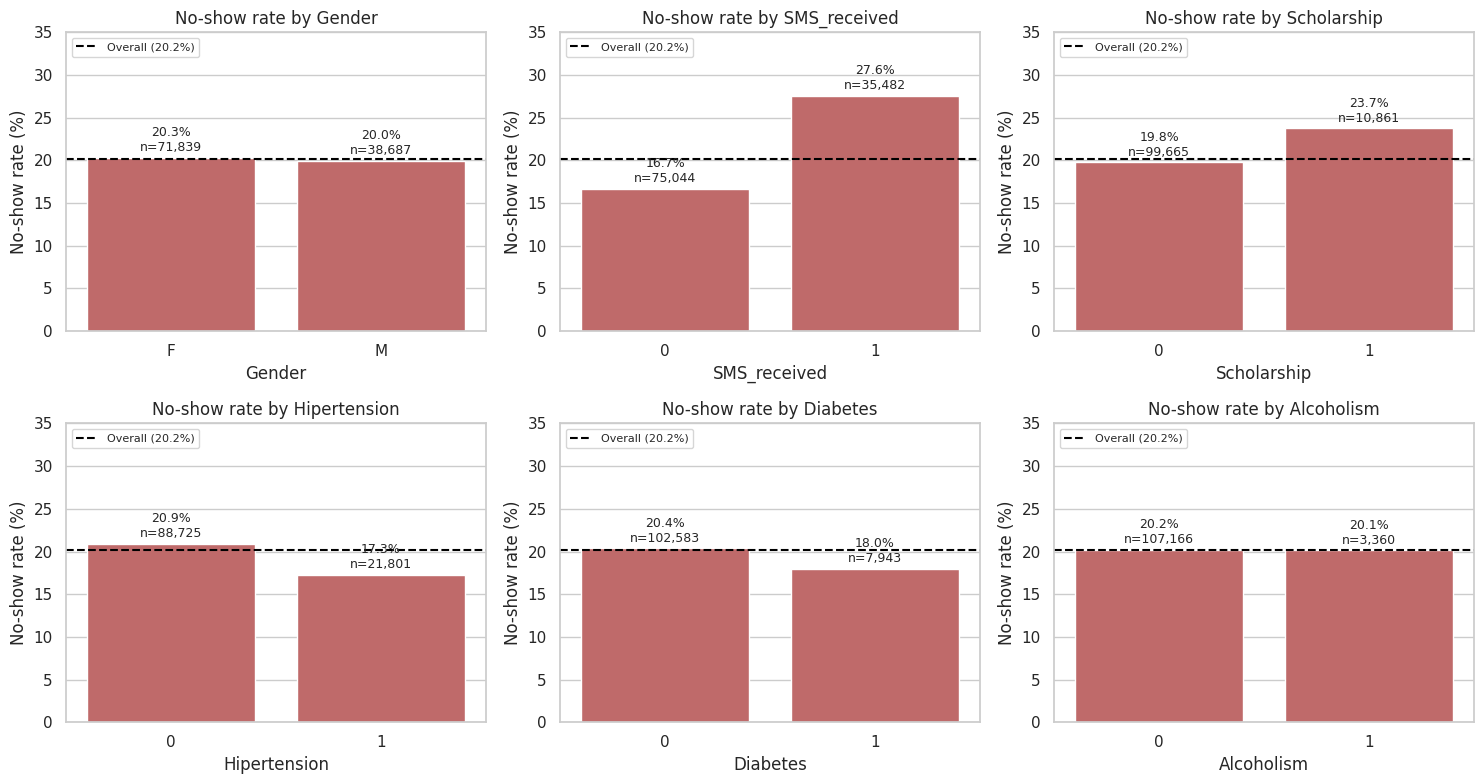

In [7]:
## your code here
overall = eda["NoShow"].mean()
print(f"Overall no-show rate: {overall:.2%}  (n = {len(eda):,})")

def rate_table(col):
    t = eda.groupby(col)["NoShow"].agg(n="size", missed="sum", no_show_rate="mean")
    t["no_show_rate"] = (t["no_show_rate"] * 100).round(2)
    return t

chars = ["Gender", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "Alcoholism"]
for c in chars:
    print(f"\n{c}"); display(rate_table(c))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(axes.ravel(), chars):
    t = rate_table(c)
    sns.barplot(x=t.index.astype(str), y=t["no_show_rate"], ax=a, color="indianred")
    a.axhline(overall * 100, color="black", ls="--", label=f"Overall ({overall:.1%})")
    for k, (r, n) in enumerate(zip(t["no_show_rate"], t["n"])):
        a.text(k, r + 0.4, f"{r:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=9)
    a.set(title=f"No-show rate by {c}", xlabel=c, ylabel="No-show rate (%)", ylim=(0, 35))
    a.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**(b) Age groups (2 marks):**

Next, divide patients into meaningful age groups and compare their no show rates.

,n,no_show_rate
AgeGroup,,
0-12 Child,21036,20.47
13-18 Teen,7830,26.05
19-30 Young adult,16765,24.71
31-45 Adult,21954,21.37
46-60 Middle-aged,23179,17.82
61-75 Older adult,14370,14.86
76+ Elderly,5392,16.14


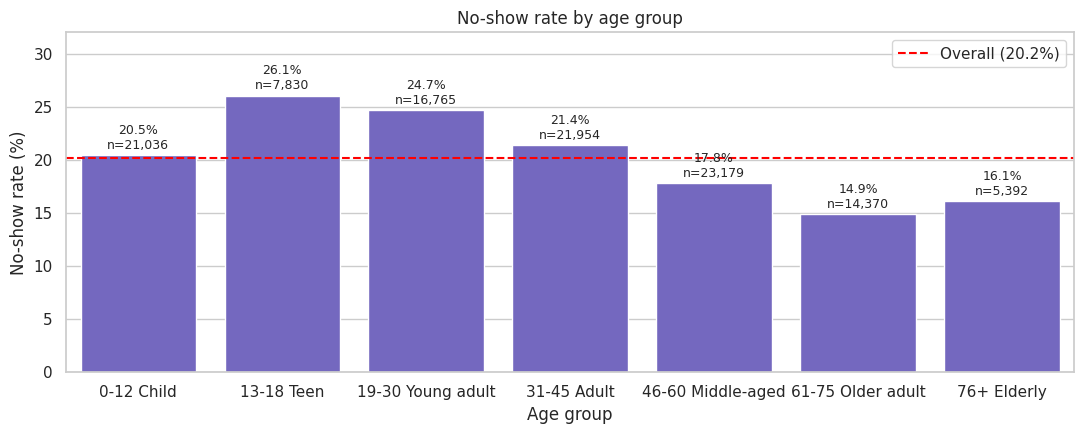

In [8]:
## your code here
bins   = [0, 12, 18, 30, 45, 60, 75, 120]
labels = ["0-12 Child", "13-18 Teen", "19-30 Young adult", "31-45 Adult",
          "46-60 Middle-aged", "61-75 Older adult", "76+ Elderly"]
eda["AgeGroup"] = pd.cut(eda["Age"], bins=bins, labels=labels, right=True, include_lowest=True)

age_tbl = eda.groupby("AgeGroup", observed=True)["NoShow"].agg(n="size", no_show_rate="mean")
age_tbl["no_show_rate"] = (age_tbl["no_show_rate"] * 100).round(2)
display(age_tbl)

plt.figure(figsize=(11, 4.5))
ax = sns.barplot(x=age_tbl.index.astype(str), y=age_tbl["no_show_rate"], color="slateblue")
plt.axhline(overall * 100, color="red", ls="--", label=f"Overall ({overall:.1%})")
for k, (r, n) in enumerate(zip(age_tbl["no_show_rate"], age_tbl["n"])):
    ax.text(k, r + 0.3, f"{r:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=9)
plt.title("No-show rate by age group"); plt.xlabel("Age group"); plt.ylabel("No-show rate (%)")
plt.ylim(0, 32); plt.legend(); plt.tight_layout(); plt.show()

**(c) Intersectional analysis (3 marks):**

Finally, perform an intersectional analysis of `Gender` × `Age Group` and visualize the resulting no-show rates.


No-show rate (%) by Age group x Gender:


Gender,F,M,Gap (F - M)
AgeGroup,,,
0-12 Child,20.45,20.49,-0.04
13-18 Teen,25.55,26.92,-1.37
19-30 Young adult,24.93,24.08,0.85
31-45 Adult,21.35,21.43,-0.08
46-60 Middle-aged,17.89,17.68,0.21
61-75 Older adult,15.47,13.64,1.83
76+ Elderly,16.09,16.22,-0.13


Number of appointments:


Gender,F,M
AgeGroup,,
0-12 Child,10022,11014
13-18 Teen,4932,2898
19-30 Young adult,12417,4348
31-45 Adult,15383,6571
46-60 Middle-aged,15811,7368
61-75 Older adult,9633,4737
76+ Elderly,3641,1751


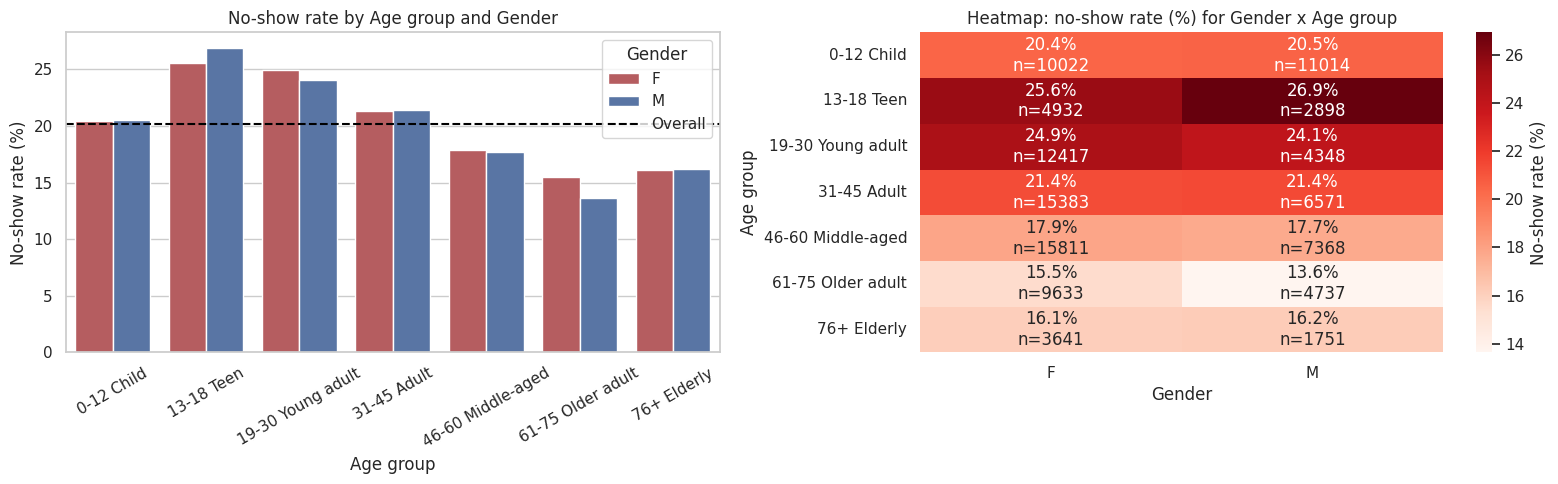

In [9]:
## your code here
inter = (eda.groupby(["AgeGroup", "Gender"], observed=True)["NoShow"]
            .agg(n="size", no_show_rate="mean").reset_index())
inter["no_show_rate"] = (inter["no_show_rate"] * 100).round(2)
rate_pivot = inter.pivot(index="AgeGroup", columns="Gender", values="no_show_rate")
n_pivot    = inter.pivot(index="AgeGroup", columns="Gender", values="n")
rate_pivot["Gap (F - M)"] = (rate_pivot["F"] - rate_pivot["M"]).round(2)
print("No-show rate (%) by Age group x Gender:"); display(rate_pivot)
print("Number of appointments:"); display(n_pivot)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=inter, x="AgeGroup", y="no_show_rate", hue="Gender", ax=ax[0], palette=["#c44e52", "#4c72b0"])
ax[0].axhline(overall * 100, color="black", ls="--", label="Overall")
ax[0].set(title="No-show rate by Age group and Gender", xlabel="Age group", ylabel="No-show rate (%)")
ax[0].tick_params(axis="x", rotation=30); ax[0].legend(title="Gender")

annot = rate_pivot[["F", "M"]].round(1).astype(str) + "%\nn=" + n_pivot.astype(str)
sns.heatmap(rate_pivot[["F", "M"]], annot=annot, fmt="", cmap="Reds", ax=ax[1],
            cbar_kws={"label": "No-show rate (%)"})
ax[1].set(title="Heatmap: no-show rate (%) for Gender x Age group", xlabel="Gender", ylabel="Age group")
plt.tight_layout(); plt.show()

**(d) Interpretation (2 marks):**

Based on your analysis, describe the most notable differences you observe between groups. Explain whether examining the intersection of two characteristics reveals anything that may not be apparent when looking at each characteristic individually.

**Answer:**

- **The strongest differences are by SMS and age, not gender.** the overall no-show rate is 20.19% (n = 110,526). Gender barely matters (F 20.31% vs M 19.97%). patients who received an SMS miss *more* often (27.57% vs 16.70%). this is not becuase SMS causes absence: B4(b) shows that SMS is only sent when the booking is at least 3 days ahead, and long waits have more no-shows. comparing only appointments with WaitingDays ≥ 3, the SMS group actually misses *less* (27.6% vs 32.7%). Bolsa Família recipients miss more (23.74% vs 19.81%), while patients with hypertension (17.30%) or diabetes (18.00%) miss less, which suggests chronic-care patients are more engaged. Alcoholism makes no difference (20.15% vs 20.19%).
- **Age groups show a clear gradient:** the rate peaks for teens (26.05%) and young adults 19–30 (24.71%) and falls to 14.86% for ages 61–75, a gap of about 11 percentage points.
- **The intersection adds a little, but mostly confirms that age drives the pattern.** within every age group the female–male gap is small (under 2 points). the largest gaps are among ages 61–75, where women miss more (15.47% vs 13.64%), and teens 13–18, where boys miss more (26.92% vs 25.55%). these opposite-direction differences cancel out in the overall gender comparison, so they would be invisible if we looked at gender alone. the intersection also exposes group-size imbalance that the marginals hide: women outnumber men almost 3 to 1 among young adults (12,417 vs 4,348), so the overall gender figure is weighted towards young women. differences this small, especialy for men 76+ (n = 1,751), should be read as tentative rather than conclusive.

## **B4. Temporal Analysis and Feature Engineering (10 Marks)**

The dataset contains information about when an appointment was scheduled and when it was supposed to take place.

**(a) Temporal features (3 marks):**

Convert ScheduledDay and AppointmentDay into appropriate datetime formats and create meaningful temporal features such as:

*  day of the week
*  month
*  scheduled hour


In [10]:
## your code here
df["ScheduledDay"]   = pd.to_datetime(df["ScheduledDay"])            # full timestamp (UTC)
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])          # date only (time = 00:00:00)
print(df[["ScheduledDay", "AppointmentDay"]].dtypes, "\n")

df["ScheduledDate"]     = df["ScheduledDay"].dt.normalize()
df["ApptDayOfWeek"]     = df["AppointmentDay"].dt.day_name()
df["ApptDayOfWeekNum"]  = df["AppointmentDay"].dt.dayofweek          # 0 = Monday
df["ApptMonth"]         = df["AppointmentDay"].dt.month_name()
df["ScheduledHour"]     = df["ScheduledDay"].dt.hour
df["ScheduledDayOfWeek"] = df["ScheduledDay"].dt.day_name()
df["ScheduledMonth"]    = df["ScheduledDay"].dt.month_name()

print("Scheduled range  :", df["ScheduledDay"].min(), "->", df["ScheduledDay"].max())
print("Appointment range:", df["AppointmentDay"].min().date(), "->", df["AppointmentDay"].max().date())
display(df[["ScheduledDay", "AppointmentDay", "ApptDayOfWeek", "ApptMonth",
            "ScheduledHour", "ScheduledDayOfWeek", "ScheduledMonth"]].head())
print("\nAppointments by appointment month:"); print(df["ApptMonth"].value_counts().to_string())
print("\nAppointments by scheduled hour:"); print(df["ScheduledHour"].value_counts().sort_index().to_string())

ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object 

Scheduled range  : 2015-11-10 07:13:56+00:00 -> 2016-06-08 20:07:23+00:00
Appointment range: 2016-04-29 -> 2016-06-08


,ScheduledDay,AppointmentDay,ApptDayOfWeek,ApptMonth,ScheduledHour,ScheduledDayOfWeek,ScheduledMonth
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,Friday,April,18,Friday,April
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,Friday,April,16,Friday,April
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,Friday,April,16,Friday,April
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,Friday,April,17,Friday,April
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,Friday,April,16,Friday,April



Appointments by appointment month:
ApptMonth
May      80841
June     26451
April     3235

Appointments by scheduled hour:
ScheduledHour
6      1578
7     19213
8     15349
9     12823
10    11056
11     8462
12     5422
13     9036
14     9127
15     8079
16     5542
17     2909
18     1340
19      488
20      100
21        3


**(b) Waiting time (3 marks):**

Create a new feature, WaitingDays, representing the number of days between the scheduled date and appointment date. Investigate the distribution of WaitingDays and examine how the no show rate changes across different waiting time groups


Rowsss withh negative WaitingDays (bookedd after the appointmenttt date): 5


,ScheduledDay,AppointmentDay,WaitingDays,No-show
27033,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,-1,Yes
55226,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,-1,Yes
64175,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,-1,Yes
71533,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,-6,Yes
72362,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,-1,Yes


count    110521.00
mean         10.18
std          15.26
min           0.00
25%           0.00
50%           4.00
75%          15.00
max         179.00
Name: WaitingDays, dtype: float64
Same-day appointments (WaitingDays = 0): 0.349


,n,no_show_rate
WaitGroup,,
Same day,38562,4.65
1-3,14675,22.89
4-7,17510,25.20
8-14,12025,30.47
15-30,17371,32.59
31-60,8283,34.15
61+,2095,28.45


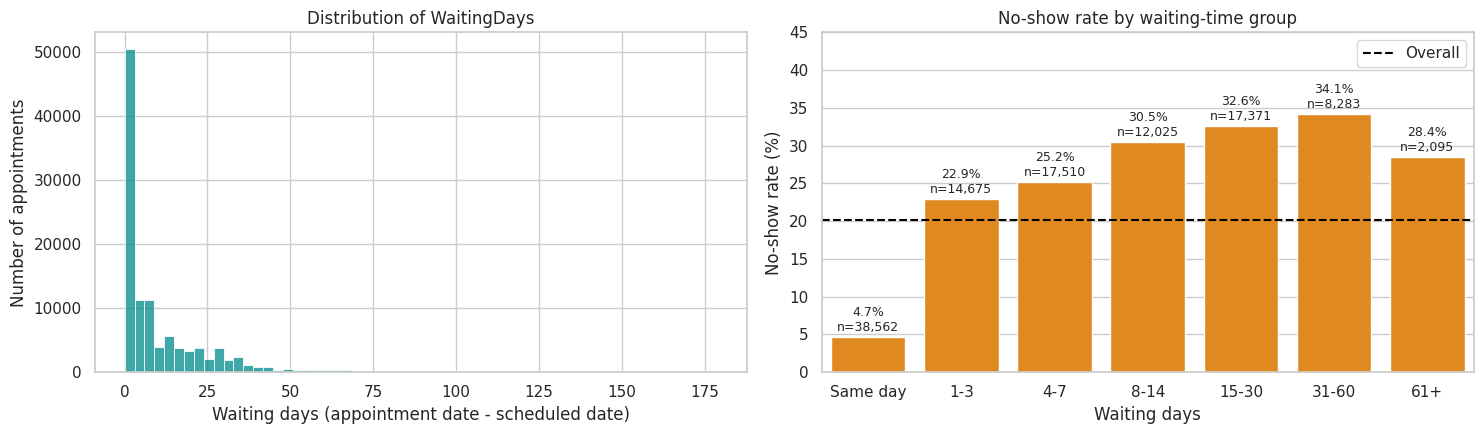

WaitingDays by SMS_received:


,count,mean,std,min,25%,50%,75%,max
SMS_received,,,,,,,,
0,75039.0,6.0,12.3,0.0,0.0,0.0,6.0,179.0
1,35482.0,19.0,17.0,3.0,7.0,14.0,27.0,179.0


No-show rate by SMS_received, only appointments with WaitingDays >= 3 (like-for-like comparison):


,n,no_show_rate
SMS_received,,
0,24539,32.69
1,35482,27.57


In [11]:
## your code here
df["WaitingDays"] = (df["AppointmentDay"] - df["ScheduledDate"]).dt.days
print("Rowsss withh negative WaitingDays (bookedd after the appointmenttt date):", (df["WaitingDays"] < 0).sum())
display(df.loc[df["WaitingDays"] < 0, ["ScheduledDay", "AppointmentDay", "WaitingDays", "No-show"]])

# Keep only valid rows for the analysis from here on
df = df[(df["WaitingDays"] >= 0) & (df["Age"] >= 0)].copy()
print(df["WaitingDays"].describe().round(2))
print("Same-day appointments (WaitingDays = 0):", (df["WaitingDays"] == 0).mean().round(3))

wbins   = [-1, 0, 3, 7, 14, 30, 60, 200]
wlabels = ["Same day", "1-3", "4-7", "8-14", "15-30", "31-60", "61+"]
df["WaitGroup"] = pd.cut(df["WaitingDays"], bins=wbins, labels=wlabels)
wait_tbl = df.groupby("WaitGroup", observed=True)["NoShow"].agg(n="size", no_show_rate="mean")
wait_tbl["no_show_rate"] = (wait_tbl["no_show_rate"] * 100).round(2)
display(wait_tbl)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df["WaitingDays"], bins=60, ax=ax[0], color="darkcyan")
ax[0].set(title="Distribution of WaitingDays", xlabel="Waiting days (appointment date - scheduled date)",
          ylabel="Number of appointments")
sns.barplot(x=wait_tbl.index.astype(str), y=wait_tbl["no_show_rate"], ax=ax[1], color="darkorange")
for k, (r, n) in enumerate(zip(wait_tbl["no_show_rate"], wait_tbl["n"])):
    ax[1].text(k, r + 0.4, f"{r:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=9)
ax[1].axhline(df["NoShow"].mean() * 100, color="black", ls="--", label="Overall")
ax[1].set(title="No-show rate by waiting-time group", xlabel="Waiting days", ylabel="No-show rate (%)", ylim=(0, 45))
ax[1].legend()
plt.tight_layout(); plt.show()

# SMS reminders are only sent when the appointment is booked >= 3 days ahead, so SMS is confounded with waiting time
print("WaitingDays by SMS_received:")
display(df.groupby("SMS_received")["WaitingDays"].describe().round(1))
sms_fair = (df[df["WaitingDays"] >= 3].groupby("SMS_received")["NoShow"]
              .agg(n="size", no_show_rate="mean"))
sms_fair["no_show_rate"] = (sms_fair["no_show_rate"] * 100).round(2)
print("No-show rate by SMS_received, only appointments with WaitingDays >= 3 (like-for-like comparison):")
display(sms_fair)

**(c) Temporal patterns (2 marks):**

Investigate whether the no show rate varies across days of the week or months.


By appointment day of week:


,n,no_show_rate
ApptDayOfWeek,,
Monday,22713,20.64
Tuesday,25638,20.09
Wednesday,25866,19.69
Thursday,17246,19.35
Friday,19019,21.23
Saturday,39,23.08


By appointment monthhhh:


,n,no_show_rate
ApptMonth,,
April,3235,19.57
May,80836,20.78
June,26450,18.46


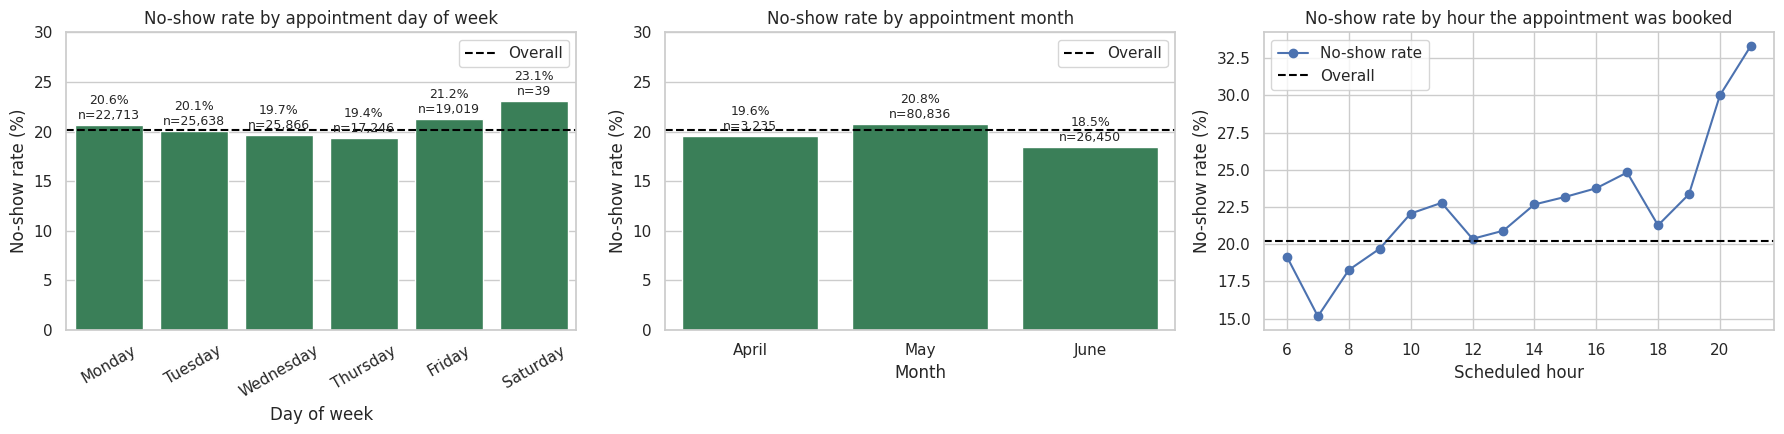

By scheduled hourrrr:


ScheduledHour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
n,1577.00,19213.00,15348.00,12823.0,11055.00,8462.00,5422.00,9034.00,9126.00,8079.00,5542.00,2909.00,1340.00,488.00,100.0,3.00
no_show_rate,19.15,15.15,18.27,19.7,22.06,22.78,20.36,20.91,22.67,23.18,23.76,24.82,21.27,23.36,30.0,33.33


In [12]:
## your code here
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
dow_tbl = (df.groupby("ApptDayOfWeek")["NoShow"].agg(n="size", no_show_rate="mean")
             .reindex([d for d in order if d in df["ApptDayOfWeek"].unique()]))
dow_tbl["no_show_rate"] = (dow_tbl["no_show_rate"] * 100).round(2)
print("By appointment day of week:"); display(dow_tbl)

month_tbl = (df.groupby("ApptMonth")["NoShow"].agg(n="size", no_show_rate="mean")
               .reindex(["April", "May", "June"]))
month_tbl["no_show_rate"] = (month_tbl["no_show_rate"] * 100).round(2)
print("By appointment monthhhh:"); display(month_tbl)

hour_tbl = df.groupby("ScheduledHour")["NoShow"].agg(n="size", no_show_rate="mean")
hour_tbl["no_show_rate"] = (hour_tbl["no_show_rate"] * 100).round(2)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, t, title, xl in [(ax[0], dow_tbl, "No-show rate by appointment day of week", "Day of week"),
                        (ax[1], month_tbl, "No-show rate by appointment month", "Month")]:
    sns.barplot(x=t.index, y=t["no_show_rate"], ax=a, color="seagreen")
    for k, (r, n) in enumerate(zip(t["no_show_rate"], t["n"])):
        a.text(k, r + 0.3, f"{r:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=9)
    a.axhline(df["NoShow"].mean() * 100, color="black", ls="--", label="Overall")
    a.set(title=title, xlabel=xl, ylabel="No-show rate (%)", ylim=(0, 30)); a.legend()
ax[0].tick_params(axis="x", rotation=30)
ax[2].plot(hour_tbl.index, hour_tbl["no_show_rate"], marker="o", label="No-show rate")
ax[2].axhline(df["NoShow"].mean() * 100, color="black", ls="--", label="Overall")
ax[2].set(title="No-show rate by hour the appointment was booked", xlabel="Scheduled hour",
          ylabel="No-show rate (%)"); ax[2].legend()
plt.tight_layout(); plt.show()
print("By scheduled hourrrr:"); display(hour_tbl.T)


**(d) Feature usefulness (2 marks):**

Based on your analysis, identify the temporal or engineered feature(s) that appear potentially useful for predicting appointment no-shows and briefly explain why.

**Answer:**

- **WaitingDays is by far the most useful engineered feature.** Same-day appointments have a no-show rate of only 4.65% (35% of all appointments), and the rate rises steadily to 22.89% (1–3 days), 30.47% (8–14 days) and 34.15% (31–60 days). that is a roughly seven-fold difference, much larger than for any original variable. it is also known at booking time, so it is safe to use for an evening-before call list. its effect is non-linear (it levels off and dips to 28.45% for 61+ days), so binning or a tree-based model may capture it better than a linear term.
- **ScheduledHour is moderately useful.** appointments booked early in the morning (07:00, 15.15%) are missed less often than those booked in the late afternoon (16:00–17:00, about 24–25%). this may reflect walk-in bookings made in person compared with later phone bookings.
- **Day of week and month are weak.** Weekdays vary only between 19.35% (Thursday) and 21.23% (Friday). Saturday has just 39 appointments, too few to trust. Month (18.5–20.8%) mostly reflects that the data cover only 3 months, with April and June only partly covered. so it would not generalise to other periods and should not be used as a feature. day of week can be kept as a low-cost categorical feature.
- **WaitingDays should be used together with SMS_received** so that a model can seperate the effect of the reminder from the effect of the waiting time that determines who gets one.

## **B5. Preparing the Dataset for Modelling (10 Marks)**

Prepare the dataset for use in a machine-learning model that predicts whether a patient will miss an appointment.

Your preprocessing should include:

* Encode the target variable No show into an appropriate numerical representation (1 Mark).
* Select the features you would use for modelling and briefly justify any important exclusions (2 Marks).
* Split the data into training and test sets (1 Mark).
* Apply one-hot encoding to appropriate categorical variables (1 Mark).
* Apply Min-Max normalization to appropriate numerical features (1 Mark).
* Organize the preprocessing so that all transformations are fitted only on the training data and then applied to the test data (1 Mark).
* Show the shape and a sample of the resulting modelling-ready training and test datasets (1 Mark).

In [13]:
## your code here
data = df.copy()

# (a) Target encodingg: 1 = missed (No-show == "Yes"), 0 = attended
data["target"] = data["No-show"].map({"Yes": 1, "No": 0})
print("Target distribution:\n", data["target"].value_counts(normalize=True).round(4).to_string())

# (b) Feature selection
data["Handcap"] = (data["Handcap"] > 0).astype(int)     # 0-4 count -> binary disability flag (few rows > 1)
numeric_features     = ["Age", "WaitingDays", "ScheduledHour"]
categorical_features = ["Gender", "Neighbourhood", "ApptDayOfWeek"]
binary_features      = ["Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "SMS_received"]
features = numeric_features + categorical_features + binary_features
X = data[features]
y = data["target"]

# (c) Train/test split grouped by patient: a patient's appointments are all in train OR all in test,
#     so the model cannot memorise a patient's behaviour (group leakage, Part A5 step 4)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=data["PatientId"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Patients in both train and test:",
      len(set(data["PatientId"].iloc[train_idx]) & set(data["PatientId"].iloc[test_idx])))
print(f"\nTrain: {X_train.shape}, no-show rate {y_train.mean():.4f}")
print(f"Test : {X_test.shape}, no-show rate {y_test.mean():.4f}")

# (d)-(f) One-hot + Min-Max inside a ColumnTransformer, fitteed on the training data only
preprocess = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ],
    verbose_feature_names_out=False,
)
pipeline = Pipeline([("preprocess", preprocess)])   # a model step can be appended laterr

pipeline.fit(X_train)                               # learns min/max and categories from TRAIN only
feature_names = pipeline.get_feature_names_out()
X_train_ready = pd.DataFrame(pipeline.transform(X_train), columns=feature_names, index=X_train.index)
X_test_ready  = pd.DataFrame(pipeline.transform(X_test),  columns=feature_names, index=X_test.index)

scaler = pipeline.named_steps["preprocess"].named_transformers_["num"]
print("\nMin-Max parameters learned from the training set only:")
print(pd.DataFrame({"min": scaler.data_min_, "max": scaler.data_max_}, index=numeric_features))

# (g) Shapees and sampless
print("\nX_train_ready:", X_train_ready.shape, "| y_train:", y_train.shape)
print("X_test_ready :", X_test_ready.shape, "| y_test:", y_test.shape)
print("\nTraining sample:"); display(X_train_ready.head())
print("Test sample:");     display(X_test_ready.head())
print("Test-set numeric ranges after scaling (can fall slightly outside [0, 1] because the scaler never saw test data):")
print(X_test_ready[numeric_features].agg(["min", "max"]).round(3))

Target distribution:
 target
0    0.7981
1    0.2019
Patients in both train and test: 0

Train: (88441, 12), no-show rate 0.2012
Test : (22080, 12), no-show rate 0.2046

Min-Max parameters learned from the training set only:
               min    max
Age            0.0  115.0
WaitingDays    0.0  179.0
ScheduledHour  6.0   21.0

X_train_ready: (88441, 97) | y_train: (88441,)
X_test_ready : (22080, 97) | y_test: (22080,)

Training sample:


,Age,WaitingDays,ScheduledHour,Gender_F,Gender_M,Neighbourhood_AEROPORTO,Neighbourhood_ANDORINHAS,Neighbourhood_ANTÔNIO HONÓRIO,Neighbourhood_ARIOVALDO FAVALESSA,Neighbourhood_BARRO VERMELHO,...,ApptDayOfWeek_Saturday,ApptDayOfWeek_Thursday,ApptDayOfWeek_Tuesday,ApptDayOfWeek_Wednesday,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
0,0.539130,0.000000,0.800000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.486957,0.000000,0.666667,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.539130,0.000000,0.666667,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.069565,0.000000,0.733333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.660870,0.011173,0.133333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Test sample:


,Age,WaitingDays,ScheduledHour,Gender_F,Gender_M,Neighbourhood_AEROPORTO,Neighbourhood_ANDORINHAS,Neighbourhood_ANTÔNIO HONÓRIO,Neighbourhood_ARIOVALDO FAVALESSA,Neighbourhood_BARRO VERMELHO,...,ApptDayOfWeek_Saturday,ApptDayOfWeek_Thursday,ApptDayOfWeek_Tuesday,ApptDayOfWeek_Wednesday,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
4,0.486957,0.000000,0.666667,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
6,0.200000,0.011173,0.600000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11,0.252174,0.016760,0.133333,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
13,0.243478,0.005587,0.533333,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,0.130435,0.016760,0.133333,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Test-set numeric ranges after scaling (can fall slightly outside [0, 1] because the scaler never saw test data):
      Age  WaitingDays  ScheduledHour
min  0.00          0.0          0.000
max  0.87          1.0          0.933


Explain why fitting preprocessing transformations on the complete dataset before splitting into training and test sets can lead to data leakage (2 Marks).

**Answer:**

Preprocessing transformations *learn parameters* from the data they are fitted on: MinMaxScaler learns each column's minimum and maximum, StandardScaler the mean and standard deviation, OneHotEncoder the listtt of categories, and an imputer the fill values. if they are fitted on the complete dataset before splitting, those parameters are partly computed from the test rows, so information about the test set leaks into the training features. this is train–test contamination. for example, a test patient with an extreme age or waiting time would stretch the min/max, so the scaled training values already "know" the test range (as in A6.2, where age 90 looked tame at 1.51 instead of 4.92). the model is then evaluated on data that are not really unseen. the reported performance is optimistic compared with what we would get in deployment, where future patients are never available at fitting time. In our pipeline this is avoided by fitting the `ColumnTransformer` only on `X_train` and applying `transform()` to `X_test` (which is why a test value could fall outside [0, 1]), and by splitting by `PatientId` sooo that no patient is in both sets.